# 🤖 02 - Dueling Double Deep Q-Network (DDQN) for Employee Retention Policy

**Author**: Parth Jain  
**Approach**: Deep Reinforcement Learning for Retention Policy & State-Action Optimization  
**Key Architectures**: Dueling DDQN + Prioritized Experience Replay Buffer + Custom Environment  

---

In [16]:
import tensorflow as tf
import time

# Test CPU vs GPU performance
cpu = tf.device('/CPU:0')
gpu = tf.device('/GPU:0')

# Large matrix multiplication
matrix_size = (10000, 10000)

def benchmark(device):
    with device:
        a = tf.random.normal(matrix_size)
        b = tf.random.normal(matrix_size)
        start = time.time()
        c = tf.matmul(a, b)  # Matrix multiplication
        tf.experimental.numpy.sum(c)  # Force computation
        end = time.time()
        print(f"Computation time on {device}: {end - start:.4f} seconds")

print("Benchmarking TensorFlow computation...")
benchmark(cpu)
benchmark(gpu)


Benchmarking TensorFlow computation...
Computation time on <tensorflow.python.eager.context._EagerDeviceContext object at 0x0000021612CCF640>: 28.0578 seconds
Computation time on <tensorflow.python.eager.context._EagerDeviceContext object at 0x0000021516EC6600>: 0.0000 seconds


In [ ]:
# Cell 1: Install required libraries (if needed)
!pip install tensorflow keras pandas numpy scikit-learn matplotlib seaborn transformers

In [2]:
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available: 1


In [1]:
# Cell 2: Import libraries and set seeds for reproducibility
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer

np.random.seed(42)
tf.random.set_seed(42)

print("Imports done")

Imports done


In [ ]:
pip install tensorflow-gpu


In [2]:


# Load data dynamically from local or parent directory
import os
data_path = "data/data.csv" if os.path.exists("data/data.csv") else ("../data/data.csv" if os.path.exists("../data/data.csv") else "data.csv")
data = pd.read_csv(data_path)  # Ensure the filename matches
print(data.head())  # Display first 5 rows


   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

In [ ]:
# Cell 3: Load the CSV file (make sure to upload data.csv)
# If using google.colab, you can use the files.upload() widget.
from google.colab import files
uploaded = files.upload()  # Upload your data.csv file

# Assuming your CSV has 1470 samples and 35 columns, and one column named 'target'
# Load data dynamically from local or parent directory
import os
data_path = "data/data.csv" if os.path.exists("data/data.csv") else ("../data/data.csv" if os.path.exists("../data/data.csv") else "data.csv")
data = pd.read_csv(data_path)
print("Data shape:", data.shape)



In [7]:
print("Unique values in data['Attrition']:", data['Attrition'].unique())


Unique values in data['Attrition']: [nan]


In [8]:
# Clean the Attrition column: strip whitespace and convert to lowercase
data['Attrition'] = data['Attrition'].astype(str).str.strip().str.lower()

# Map the cleaned values to numeric values
data['Attrition'] = data['Attrition'].map({'no': 0, 'yes': 1})   

# Check the mapping result
print("Unique values in data['Attrition'] after mapping:", data['Attrition'].unique())


Unique values in data['Attrition'] after mapping: [nan]


In [10]:
# Explicitly define your numerical and categorical columns.
# Replace these examples with the actual names of your numeric and categorical columns.
numerical_cols = [
    "Age", "DailyRate", "DistanceFromHome", "Education", "EmployeeCount", "EmployeeNumber",
    "EnvironmentSatisfaction", "HourlyRate", "JobInvolvement", "JobLevel", "JobSatisfaction",
    "MonthlyIncome", "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
    "RelationshipSatisfaction", "StandardHours", "StockOptionLevel", "TotalWorkingYears",
    "TrainingTimesLastYear", "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole",
    "YearsSinceLastPromotion", "YearsWithCurrManager"
]

categorical_cols = [
    "BusinessTravel", "Department", "EducationField", "Gender", "JobRole",
    "MaritalStatus", "Over18", "OverTime"
]


target_col = "Attrition"
X = data.drop(target_col, axis=1)
y = data[target_col]

# Set up a ColumnTransformer that applies scaling to numerical columns and one–hot encodes categorical columns.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"), categorical_cols)
      #  drop="first"


    ],
    remainder="passthrough"  # Optionally, pass through any columns not explicitly mentioned.
)

# Fit and transform the features
X_processed = preprocessor.fit_transform(X)
print("Processed feature shape:", X_processed.shape)
for col in categorical_cols:
    print(f"{col}: {X[col].nunique()} unique values")


# Optionally, split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_processed, y, test_size=0.2, random_state=42)
print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)



Processed feature shape: (1970, 54)
BusinessTravel: 3 unique values
Department: 3 unique values
EducationField: 6 unique values
Gender: 2 unique values
JobRole: 9 unique values
MaritalStatus: 3 unique values
OverTime: 2 unique values
Training set shape: (1576, 54)
Validation set shape: (394, 54)


In [11]:
import pandas as pd

# Suppose your labels are in a DataFrame column called 'Attrition'
data['Attrition'] = data['Attrition'].map({'no': 0, 'yes': 1})
print("Unique values in y_train:", np.unique(y_train))
print("Unique values in y_val:", np.unique(y_val))


Unique values in y_train: [nan]
Unique values in y_val: [nan]


Model: "autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 autoencoder_input (InputLay  [(None, 47)]             0         
 er)                                                             
                                                                 
 dense_11 (Dense)            (None, 128)               6144      
                                                                 
 dropout_5 (Dropout)         (None, 128)               0         
                                                                 
 dense_12 (Dense)            (None, 96)                12384     
                                                                 
 latent_vector (Dense)       (None, 74)                7178      
                                                                 
 dense_13 (Dense)            (None, 96)                7200      
                                                       

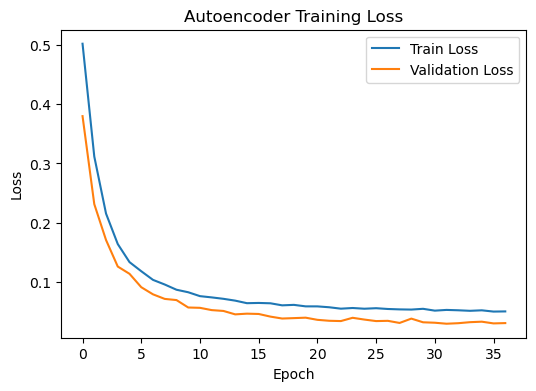

50/50 [==============================] - 0s 3ms/step
Latent features shape: (1576, 74)


In [22]:
from tensorflow import keras
from tensorflow.keras import layers
encoding_dim=74

def create_autoencoder(input_dim, encoding_dim=74):
    # Encoder
    input_layer = keras.Input(shape=(input_dim,), name="autoencoder_input")
    x = layers.Dense(128, activation='relu')(input_layer)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(96, activation='relu')(x)
    latent = layers.Dense(encoding_dim, activation='relu', name="latent_vector")(x)

    # Decoder
    x = layers.Dense(96, activation='relu')(latent)
    x = layers.Dense(128, activation='relu')(x)
    output_layer = layers.Dense(input_dim, activation='linear')(x)

    # Autoencoder Model
    autoencoder = keras.Model(input_layer, output_layer, name="autoencoder")
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    # autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-3), loss="mse")


    # Also create an encoder to extract the latent representation
    encoder = keras.Model(input_layer, latent, name="encoder")
    return autoencoder, encoder

# Suppose input_dim is determined after your preprocessing (e.g., after scaling and hotencoding)
# For example, if X_train is already defined:
input_dim = X_train.shape[1]
autoencoder, encoder = create_autoencoder(input_dim, encoding_dim=74)

autoencoder.summary()

# Train the autoencoder on your training data (you may also use validation data)
history_ae = autoencoder.fit(X_train, X_train,
                             validation_data=(X_val, X_val),
                             epochs=75,
                             batch_size=32,
                             callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
                             verbose=1)

# Plot training loss for the autoencoder
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(history_ae.history['loss'], label='Train Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Use the trained encoder to extract latent representations from X_train
X_train_latent = encoder.predict(X_train)
print("Latent features shape:", X_train_latent.shape)


In [23]:
# Print the final loss values after training
print("\nFinal Training Loss:", history_ae.history['loss'][-1])
print("Final Validation Loss:", history_ae.history['val_loss'][-1])

# Also, print loss at specific epochs (e.g., every 10 epochs)
for i in range(0, len(history_ae.history['loss']), 10):  # Every 10 epochs
    print(f"Epoch {i+1}: Train Loss = {history_ae.history['loss'][i]:.5f}, Validation Loss = {history_ae.history['val_loss'][i]:.5f}")



Final Training Loss: 0.0504097044467926
Final Validation Loss: 0.030704915523529053
Epoch 1: Train Loss = 0.50208, Validation Loss = 0.37989
Epoch 11: Train Loss = 0.07617, Validation Loss = 0.05645
Epoch 21: Train Loss = 0.05890, Validation Loss = 0.03622
Epoch 31: Train Loss = 0.05171, Validation Loss = 0.03132


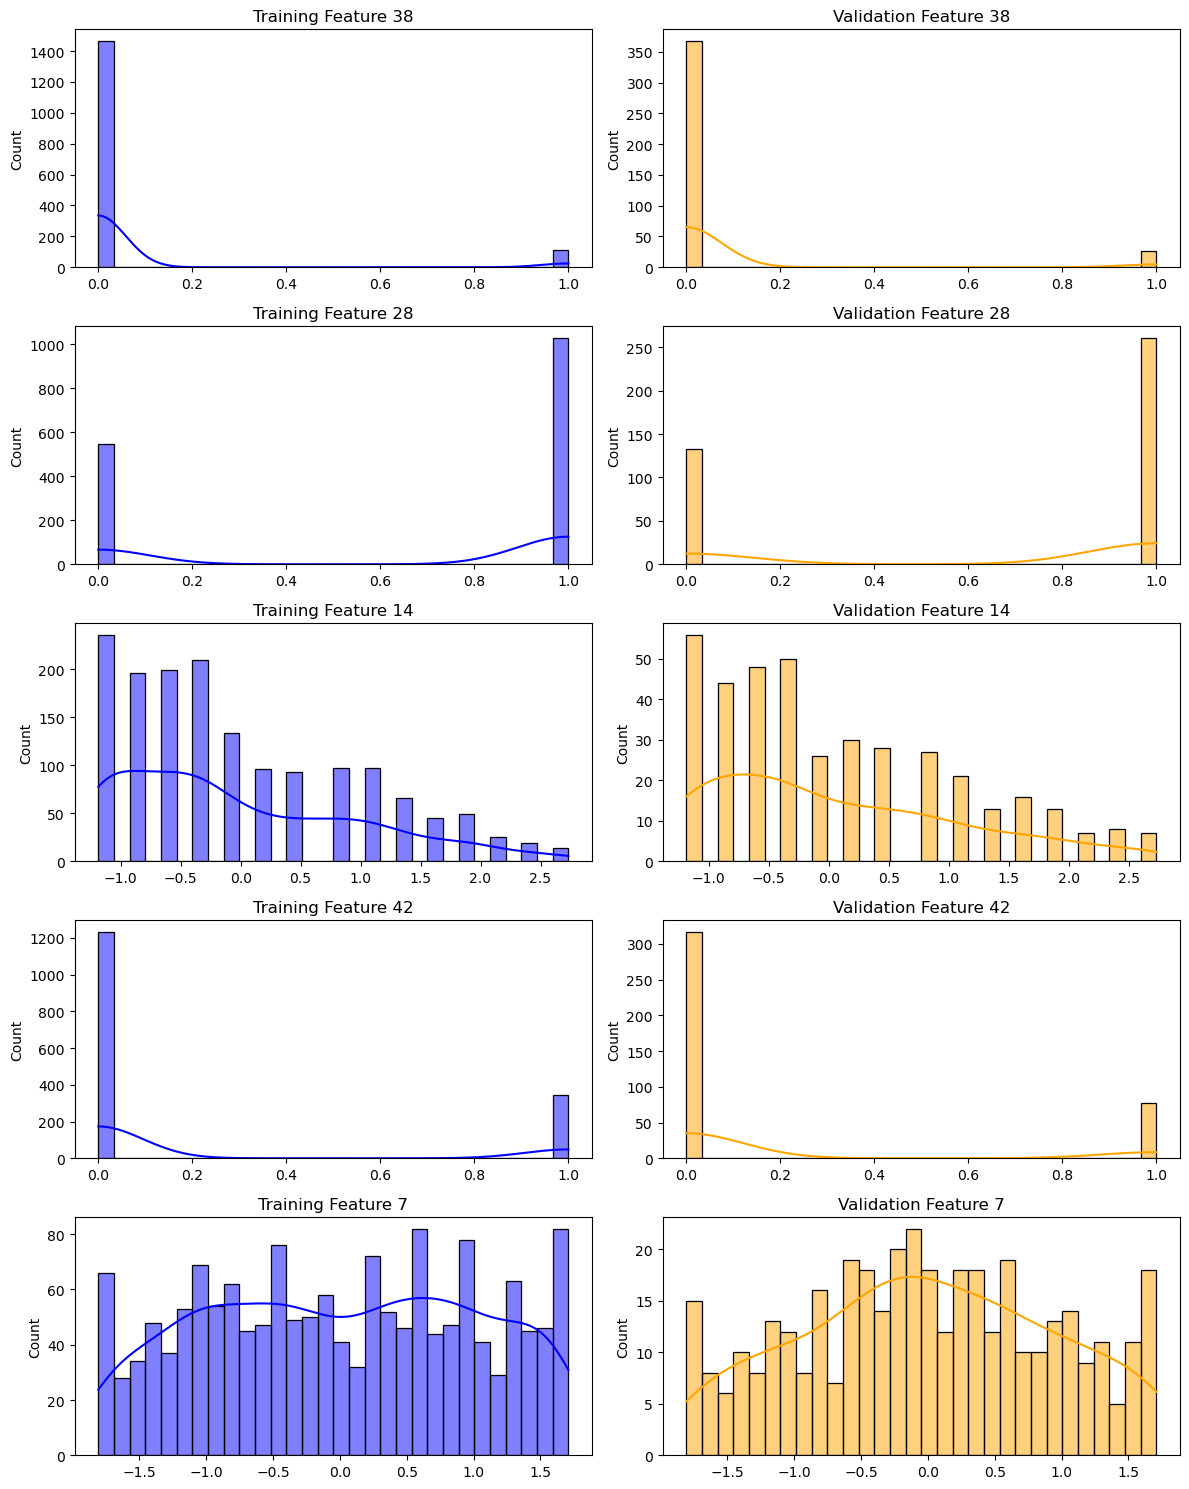

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select a few random features to compare
num_features_to_plot = min(5, X_train.shape[1])  # Plot up to 5 features

fig, axes = plt.subplots(num_features_to_plot, 2, figsize=(12, num_features_to_plot * 3))

for i in range(num_features_to_plot):
    feature_idx = np.random.randint(0, X_train.shape[1])  # Random feature index

    # Training Data Distribution
    sns.histplot(X_train[:, feature_idx], bins=30, kde=True, ax=axes[i, 0], color='blue')
    axes[i, 0].set_title(f"Training Feature {feature_idx}")

    # Validation Data Distribution
    sns.histplot(X_val[:, feature_idx], bins=30, kde=True, ax=axes[i, 1], color='orange')
    axes[i, 1].set_title(f"Validation Feature {feature_idx}")

plt.tight_layout()
plt.show()


1/1 [==============================] - 0s 149ms/step


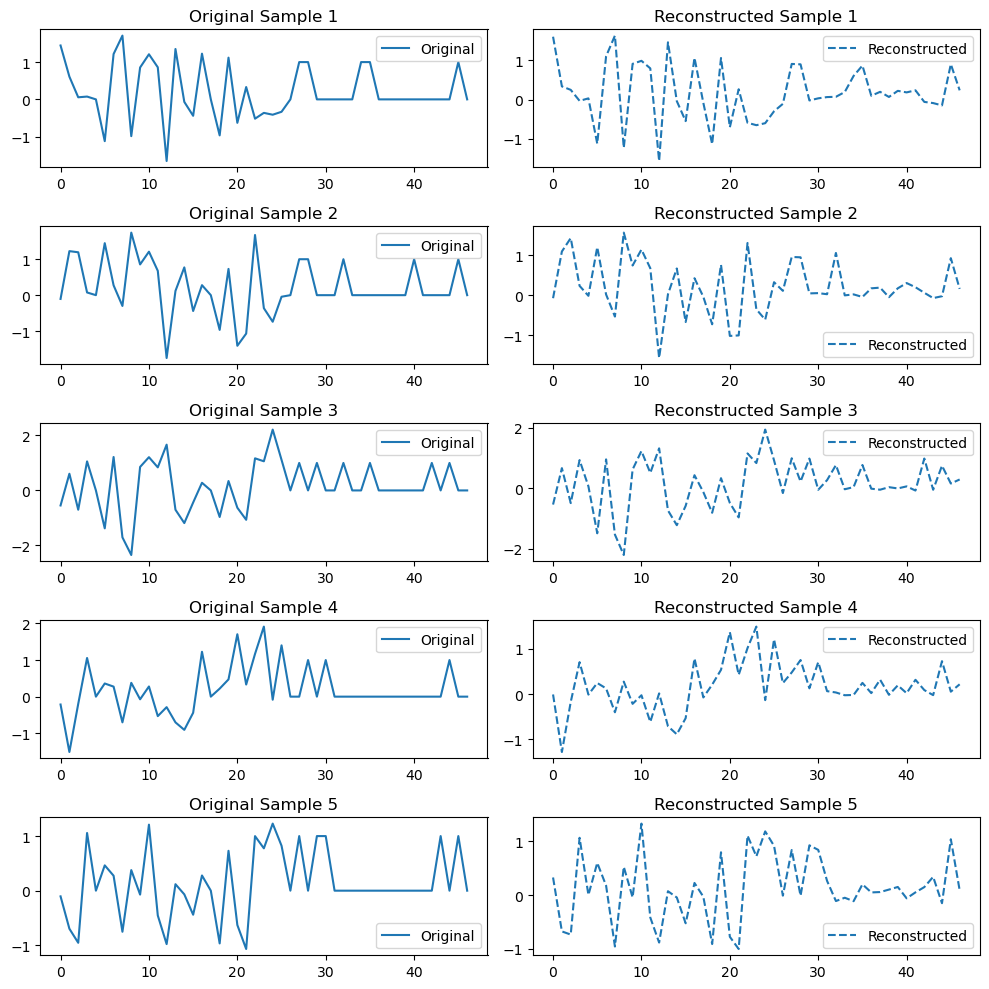

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Select a few random samples from X_test
num_samples = 5  # Choose how many examples to visualize
random_indices = np.random.choice(len(X_val), num_samples, replace=False)
original_samples = X_val[random_indices]

# Pass through the autoencoder
reconstructed_samples = autoencoder.predict(original_samples)

# Plot original vs. reconstructed samples
plt.figure(figsize=(10, num_samples * 2))

for i in range(num_samples):
    plt.subplot(num_samples, 2, 2 * i + 1)
    plt.plot(original_samples[i], label="Original")
    plt.title(f"Original Sample {i+1}")
    plt.legend()

    plt.subplot(num_samples, 2, 2 * i + 2)
    plt.plot(reconstructed_samples[i], label="Reconstructed", linestyle="dashed")
    plt.title(f"Reconstructed Sample {i+1}")
    plt.legend()

plt.tight_layout()
plt.show()


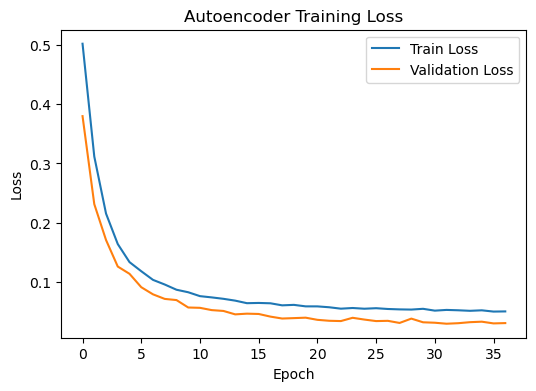

50/50 [==============================] - 0s 3ms/step
Latent features shape: (1576, 74)
Example latent vector: [0.9597636  3.5814607  3.2908168  2.712091   0.         1.8638594
 1.4949974  2.1492815  1.1542857  1.9852523  1.8873891  0.
 1.0505292  1.5038837  0.9331534  0.         3.1254992  1.074614
 1.3870829  0.         3.0233448  0.7196433  3.6814992  1.3447427
 0.3382489  1.5347222  2.4698536  1.2207891  0.         1.9215871
 1.9957691  3.5207279  0.         1.4472785  0.         2.2959065
 2.6203988  2.0944448  2.1887136  1.7973039  2.2882926  1.3678247
 1.2883102  1.281814   2.9142525  2.3297455  2.7701929  0.
 2.246731   1.2172121  2.3529954  2.4489949  0.         1.312519
 4.3087025  3.8139763  0.9154226  0.         2.20208    2.537808
 2.454269   0.87530047 1.5468318  0.8526638  1.50848    0.
 2.8716805  2.3664362  0.         2.1268451  0.         3.0151246
 0.9343513  3.058825  ]


In [26]:
# Cell 5: Plot training and validation loss for the autoencoder
plt.figure(figsize=(6,4))
plt.plot(history_ae.history['loss'], label='Train Loss') # Changed history to history_ae
plt.plot(history_ae.history['val_loss'], label='Validation Loss') # Changed history to history_ae
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# After training, get the latent features on the training data:
X_train_latent = encoder.predict(X_train)
print("Latent features shape:", X_train_latent.shape)

# (Optional) Print one example latent vector:
print("Example latent vector:", X_train_latent[0])

In [27]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Define Transformer block model – treat 74 dims as sequence tokens (74,1)
transformer_input = keras.Input(shape=(encoding_dim, 1), name="transformer_input")

# Use smaller key_dim and ensure heads divide encoding_dim
transformer_layer = layers.MultiHeadAttention(num_heads=8, key_dim=32)
attn_output = transformer_layer(transformer_input, transformer_input)

# Flatten to feed into next models
flattened_output = layers.Flatten(name="transformer_flatten")(attn_output)

# Build model
transformer_model = keras.Model(transformer_input, flattened_output, name="transformer_block")
transformer_model.summary()



Model: "transformer_block"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 transformer_input (InputLayer)  [(None, 74, 1)]     0           []                               
                                                                                                  
 multi_head_attention_2 (MultiH  (None, 74, 1)       1793        ['transformer_input[0][0]',      
 eadAttention)                                                    'transformer_input[0][0]']      
                                                                                                  
 transformer_flatten (Flatten)  (None, 74)           0           ['multi_head_attention_2[0][0]'] 
                                                                                                  
Total params: 1,793
Trainable params: 1,793
Non-trainable params: 0
______________

In [28]:
print("X_train_latent shape before reshaping:", X_train_latent.shape)


# Reshape correctly
num_samples = X_train_latent.shape[0]
X_train_latent_reshaped = X_train_latent.reshape(num_samples, encoding_dim, 1)
# equivalent - X_train_latent_reshaped = X_train_latent.reshape(-1, encoding_dim, 1)
print("Reshaped latent features shape:", X_train_latent_reshaped.shape)




# Run through Transformer
transformer_features = transformer_model.predict(X_train_latent_reshaped)
print("Transformer features shape:", transformer_features.shape)


X_train_latent shape before reshaping: (1576, 74)
Reshaped latent features shape: (1576, 74, 1)
50/50 [==============================] - 1s 9ms/step
Transformer features shape: (1576, 74)


In [29]:
w

In [33]:
X_train_latent = encoder.predict(X_train)
X_val_latent   = encoder.predict(X_val)

print("Latent train shape:", X_train_latent.shape)
print("Any NaNs in X_train_latent?", np.isnan(X_train_latent).any())
print("Any Infs in X_train_latent?", np.isinf(X_train_latent).any())


13/13 [==============================] - 0s 3ms/step
Latent train shape: (1576, 74)
Any NaNs in X_train_latent? False
Any Infs in X_train_latent? False


In [31]:
#############################################
# Cell Y: Build the Ensemble Classifier Model
#############################################
# (Assumes: 'encoder' is the trained encoder from your autoencoder,
#           and X_train, X_val, y_train, y_val are defined from your preprocessed CSV.)

# First, use the pre-trained encoder to extract latent representations.
# (If you have not already done so, run your autoencoder training cell first.)
X_train_latent = encoder.predict(X_train)
X_val_latent   = encoder.predict(X_val)
print("Latent train shape:", X_train_latent.shape)
print("Latent validation shape:", X_val_latent.shape)

# Define the ensemble model that accepts the latent features.
# Input shape is (encoding_dim,) where encoding_dim was defined (e.g., 74)
latent_input = keras.Input(shape=(encoding_dim,), name="latent_input")

# ----- MLP Branch -----
mlp_branch = layers.Dense(64, activation='relu')(latent_input)
mlp_branch = layers.Dropout(0.3)(mlp_branch)
mlp_branch = layers.Dense(32, activation='relu')(mlp_branch)

# ----- Transformer Branch -----
# Reshape the latent vector to a “sequence” with one feature per token.
transformer_branch = layers.Reshape((encoding_dim, 1), name="reshape_for_transformer")(latent_input)
# Project tokens from dimension 1 to 32.
transformer_branch = layers.Dense(32, activation='relu', name="transformer_projection")(transformer_branch)
# Now the transformer block receives tokens of shape (batch, 74, 32)
transformer_branch = TransformerBlock(embed_dim=32, num_heads=8, ff_dim=128, rate=0.1)(transformer_branch)
# Flatten the transformer output.
transformer_branch = layers.Flatten(name="flatten_transformer")(transformer_branch)


# ----- Ensemble by Concatenation -----
merged = layers.Concatenate(name="concatenate_branches")([mlp_branch, transformer_branch])
x = layers.Dense(64, activation='relu')(merged)
x = layers.Dropout(0.3)(x)
x = layers.Dense(32, activation='relu')(x)
# Final classification layer: binary output (Attrition: yes/no)
output = layers.Dense(1, activation='sigmoid', name="output")(x)

ensemble_model = keras.Model(inputs=latent_input, outputs=output, name="Ensemble_Model")
ensemble_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                         loss="binary_crossentropy",
                         metrics=["accuracy"])

ensemble_model.summary()

#############################################
# Cell Z: Train the Ensemble Model
#############################################
# Train the ensemble classifier on the latent features
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
]

history_ensemble = ensemble_model.fit(
    X_train_latent, y_train, 
    validation_data=(X_val_latent, y_val),
    epochs=50,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Evaluate the model on the validation set
val_loss, val_accuracy = ensemble_model.evaluate(X_val_latent, y_val, verbose=0)
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}")

13/13 [==============================] - 0s 3ms/step
Latent train shape: (1576, 74)
Latent validation shape: (394, 74)
Model: "Ensemble_Model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 latent_input (InputLayer)      [(None, 74)]         0           []                               
                                                                                                  
 reshape_for_transformer (Resha  (None, 74, 1)       0           ['latent_input[0][0]']           
 pe)                                                                                              
                                                                                                  
 dense_22 (Dense)               (None, 64)           4800        ['latent_input[0][0]']           
                                                                 

In [ ]:
# Define a DDQN (DQNN) model.
action_size = 2  # Number of possible actions

# State input for the DDQN head (you can adjust this shape as appropriate)
state_input = keras.Input(shape=(10,), name="ddqn_input")


# Value Branch: estimate state-value
value_dense = layers.Dense(64, activation="relu")(state_input)
value_output = layers.Dense(1, activation="linear")(value_dense)
# Advantage Branch: advantage for each action
advantage_dense = layers.Dense(64, activation="relu")(state_input)
advantage_output = layers.Dense(action_size, activation="linear")(advantage_dense)
# Subtract the mean advantage from the advantage output # Combine using the dueling technique: Q = value + (advantage - mean(advantage))
advantage_mean = layers.Lambda(lambda x: x - tf.reduce_mean(x, axis=1, keepdims=True))(advantage_output)
# Combine value and advantage streams
q_values = layers.Add()([value_output, advantage_mean])

# Create and compile the DDQN model
ddqn_model = keras.Model(state_input, q_values, name="DDQN_model")
ddqn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
ddqn_model.summary()



In [ ]:
# Example of concatenating transformer features with additional state features.
# For demonstration we simulate an extra 10-dim state (e.g., other sensor readings)
dummy_state = np.random.rand(X_train_latent.shape[0], 10)
# Combine transformer features (shape: (n_samples, 64)) with dummy state → (n_samples, 64+10)
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)

# Convert y_train to numerical format before splitting
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# y_processed = le.fit_transform(y)
y_train_encoded = le.fit_transform(y_train)

# our target is binary (Attrition - Yes/No)
from tensorflow.keras.losses import BinaryCrossentropy # Import the desired loss function
output_units = 1  # For binary classification
final_activation = 'sigmoid'  # For binary classification
loss_fn = BinaryCrossentropy() # Assign the desired loss function to the variable

# If our target has more than 2 classes:
# output_units = num_classes  # Replace with the number of classes in your target
# final_activation = 'softmax' # For multi-class classification

# Build a final head (a few Dense layers) for the supervised task (e.g. classification)
final_input = keras.Input(shape=(combined_state.shape[1],), name="final_input")
x = layers.Dense(128, activation='relu')(final_input)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(output_units, activation=final_activation)(x)
final_model = keras.Model(final_input, output, name="Final_Model")
final_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
final_model.summary()

# Split combined state data to match supervised target training
# Use y_train instead of y_processed
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    combined_state, y_train_encoded, test_size=0.2, random_state=42
)
# combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
#     combined_state, y_processed, test_size=0.2, random_state=42)

# Use callbacks to prevent overfitting
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]

# Train final model
history_final = final_model.fit(combined_train, y_train_supervised,
                                validation_data=(combined_val, y_val_supervised),
                                epochs=100,
                                batch_size=32,
                                callbacks=callbacks,
                                verbose=1)

# Plot the supervised training progress
plt.figure(figsize=(6,4))
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Final Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

# Evaluate on validation set
test_loss, test_accuracy = final_model.evaluate(combined_val, y_val_supervised)
print("Validation Loss: {:.4f} | Accuracy: {:.4f}".format(test_loss, test_accuracy))


# For demonstration we simulate an extra 10-dim state (e.g., other sensor readings)
dummy_state = np.random.rand(X_train_latent.shape[0], 10)
# Combine transformer features (shape: (n_samples, 64)) with dummy state → (n_samples, 64+10)
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)

'''
# Assume earlier you have:
# X_train, X_val, y_train, y_val = train_test_split(X_processed, y, test_size=0.2, random_state=42)
# and then you train your autoencoder and compute:
X_train_latent = encoder.predict(X_train)
# Reshape and predict transformer features:
X_train_latent_reshaped = X_train_latent.reshape(-1, encoding_dim, 1)
transformer_features = transformer_model.predict(X_train_latent_reshaped)

# Now simulate an extra 10-dim state for these training samples:
dummy_state = np.random.rand(X_train_latent.shape[0], 10)

# Combine transformer features and dummy state.
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)  # E.g., (1176, 64+10)

# Then build your final model (using output_units and loss_fn defined earlier).
final_input = keras.Input(shape=(combined_state.shape[1],), name="final_input")
x = layers.Dense(128, activation='relu')(final_input)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(output_units, activation=final_activation)(x)
final_model = keras.Model(final_input, output, name="Final_Model")
final_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
final_model.summary()

# IMPORTANT: Use y_train (not the full y_processed array) for supervised training.
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    combined_state, y_train, test_size=0.2, random_state=42
)

# Train the final model:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]
history_final = final_model.fit(
    combined_train, y_train_supervised,
    validation_data=(combined_val, y_val_supervised),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Plot training loss
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Final Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

# Evaluate on validation set:
test_loss, test_accuracy = final_model.evaluate(combined_val, y_val_supervised)
print("Validation Loss: {:.4f} | Accuracy: {:.4f}".format(test_loss, test_accuracy))

'''


'''
# Assume earlier you have:
# X_train, X_val, y_train, y_val = train_test_split(X_processed, y, test_size=0.2, random_state=42)
# and then you train your autoencoder and compute:
X_train_latent = encoder.predict(X_train)
# Reshape and predict transformer features:
X_train_latent_reshaped = X_train_latent.reshape(-1, encoding_dim, 1)
transformer_features = transformer_model.predict(X_train_latent_reshaped)

# Now simulate an extra 10-dim state for these training samples:
dummy_state = np.random.rand(X_train_latent.shape[0], 10)

# Combine transformer features and dummy state.
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)  # E.g., (1176, 64+10)

# Then build your final model (using output_units and loss_fn defined earlier).
final_input = keras.Input(shape=(combined_state.shape[1],), name="final_input")
x = layers.Dense(128, activation='relu')(final_input)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(output_units, activation=final_activation)(x)
final_model = keras.Model(final_input, output, name="Final_Model")
final_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
final_model.summary()

# IMPORTANT: Use y_train (not the full y_processed array) for supervised training.
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    combined_state, y_train, test_size=0.2, random_state=42
)

# Train the final model:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]
history_final = final_model.fit(
    combined_train, y_train_supervised,
    validation_data=(combined_val, y_val_supervised),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Plot training loss
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Final Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

# Evaluate on validation set:
test_loss, test_accuracy = final_model.evaluate(combined_val, y_val_supervised)
print("Validation Loss: {:.4f} | Accuracy: {:.4f}".format(test_loss, test_accuracy))

'''

'''
# --- Final Supervised Model Cell ---

# (Assuming X_train, y_train, X_train_latent, and transformer_features have been computed from X_train)

# Simulate an extra 10-dimensional state (e.g., additional sensor readings)
dummy_state = np.random.rand(X_train_latent.shape[0], 10)

# Combine transformer features (shape: (n_train, 64)) with dummy state → result shape: (n_train, 64+10)
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
print("Combined state shape:", combined_state.shape)

# Build the final head for the supervised task
final_input = keras.Input(shape=(combined_state.shape[1],), name="final_input")
x = keras.layers.Dense(128, activation='relu')(final_input)
x = keras.layers.Dropout(0.3)(x)
x = keras.layers.Dense(64, activation='relu')(x)
output = keras.layers.Dense(output_units, activation=final_activation)(x)
final_model = keras.Model(final_input, output, name="Final_Model")

# Compile the model using the previously defined loss function and optimizer
final_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'])
final_model.summary()

# IMPORTANT: Use the corresponding labels from the training split (y_train) rather than the full array.
# Perform a further train-test split on the combined_state (which was computed from X_train)
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    combined_state, y_train, test_size=0.2, random_state=42
)

# Set up callbacks to help prevent overfitting
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]

# Train the final model
history_final = final_model.fit(combined_train, y_train_supervised,
                                validation_data=(combined_val, y_val_supervised),
                                epochs=100,
                                batch_size=32,
                                callbacks=callbacks,
                                verbose=1)

# Plot training loss for the final model
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Validation Loss')
plt.title("Final Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Evaluate the final model on the validation portion
test_loss, test_accuracy = final_model.evaluate(combined_val, y_val_supervised)
print("Validation Loss: {:.4f} | Accuracy: {:.4f}".format(test_loss, test_accuracy))

'''


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from collections import deque
import random
from tensorflow.keras.losses import BinaryCrossentropy
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Dummy Data Preparation (Simulated Features + Labels)
num_samples = 1000
transformer_features = np.random.rand(num_samples, 64)
dummy_state = np.random.rand(num_samples, 10)
combined_state = np.concatenate([transformer_features, dummy_state], axis=1)
y_train = np.random.choice([0, 1], size=(num_samples,))  # Binary classification labels

# Encode labels
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# Train-Test Split
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    combined_state, y_train_encoded, test_size=0.2, random_state=42
)

# Define Supervised Model (Binary Classification)
final_input = keras.Input(shape=(combined_state.shape[1],), name="final_input")
x = layers.Dense(128, activation='relu')(final_input)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(1, activation='sigmoid')(x)
classifier_model = keras.Model(final_input, output, name="Classifier_Model")
classifier_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=BinaryCrossentropy(), metrics=['accuracy'])
classifier_model.summary()

# Train Classifier
history_final = classifier_model.fit(combined_train, y_train_supervised,
                                    validation_data=(combined_val, y_val_supervised),
                                    epochs=50, batch_size=32, verbose=1)

# Define RL Environment
class CustomEnv:
    def __init__(self, classifier_model):
        self.classifier = classifier_model  # Use trained classifier
        self.state = np.random.rand(1, combined_state.shape[1])  # Initial state
        self.steps = 0
        self.max_steps = 100

    def reset(self):
        self.state = np.random.rand(1, combined_state.shape[1])
        self.steps = 0
        return self.state

    def step(self, action):
        reward = 1 if action == 0 else -1
        classifier_confidence = self.classifier.predict(self.state, verbose=0)[0][0]
        reward += classifier_confidence  # Modify reward based on classifier output
        self.steps += 1
        done = self.steps >= self.max_steps
        self.state = np.random.rand(1, combined_state.shape[1])
        return self.state, reward, done, {}

# Initialize Environment
env = CustomEnv(classifier_model)
state_size = env.state.shape[1]
action_size = 2  # Two possible actions

def create_ddqn_model():
    state_input = keras.Input(shape=(state_size,), name="ddqn_input")
    value_dense = layers.Dense(64, activation="relu")(state_input)
    value_output = layers.Dense(1, activation="linear")(value_dense)
    advantage_dense = layers.Dense(64, activation="relu")(state_input)
    advantage_output = layers.Dense(action_size, activation="linear")(advantage_dense)
    advantage_mean = layers.Lambda(lambda x: x - tf.reduce_mean(x, axis=1, keepdims=True))(advantage_output)
    q_values = layers.Add()([value_output, advantage_mean])
    model = keras.Model(state_input, q_values, name="DDQN_Model")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return model
# value_dense = layers.Dense(32, activation="relu")(state_input)  # Reduce from 64
# advantage_dense = layers.Dense(32, activation="relu")(state_input)  # Reduce from 64

ddqn_model = create_ddqn_model()
target_model = create_ddqn_model()
target_model.set_weights(ddqn_model.get_weights())
ddqn_model.summary()


# RL Training Setup
gamma = 0.98
epsilon = 1.0
epsilon_min = 0.1
epsilon_decay = 0.995
batch_size = 32
memory = deque(maxlen=5000)
update_target_steps = 10
episodes = 325

# Store episode rewards and loss
episode_rewards = []
losses = []
epsilons = []

for episode in range(episodes):
    state = env.reset()
    total_reward = 0
    done = False
    episode_loss = []

    while not done:
        if np.random.rand() <= epsilon:
            action = random.randrange(action_size)
        else:
            q_values = ddqn_model.predict(state, verbose=0)
            action = np.argmax(q_values[0])

        next_state, reward, done, _ = env.step(action)
        memory.append((state, action, reward, next_state, done))
        state = next_state
        total_reward += reward
'''
        # Train with experience replay
        if len(memory) >= batch_size:
            minibatch = random.sample(memory, batch_size)
            # states, targets = [], []

            # for s, a, r, ns, d in minibatch:
            #     target = r + (gamma * np.amax(target_model.predict(ns, verbose=0)[0]) if not d else 0)
            #     target_f = ddqn_model.predict(s, verbose=0)
            #     target_f[0][a] = target
            #     states.append(s[0])
            #     targets.append(target_f[0])
            states, targets = [], []
            for s, a, r, ns, d in minibatch:
                target = r + (gamma * np.amax(target_model.predict(ns, verbose=0)[0]) if not d else 0)
                target_f = ddqn_model.predict(s, verbose=0)
                target_f[0][a] = target
                states.append(s[0])
                targets.append(target_f[0])


            history = ddqn_model.fit(np.array(states), np.array(targets), epochs=1, verbose=0)
            episode_loss.append(history.history["loss"][0])
        '''
        if len(memory) >= batch_size:
            minibatch = random.sample(memory, batch_size)

    # Unpacking the batch using zip
            states, actions, rewards, next_states, dones = zip(*minibatch)

    # Convert to numpy arrays for batch processing
            states = np.array(states).squeeze()
            next_states = np.array(next_states).squeeze()
            rewards = np.array(rewards)
            dones = np.array(dones, dtype=np.float32)  # Convert to float for multiplication

    # Predict next Q-values from the target model
            next_q_values = target_model.predict(next_states, verbose=0)
            max_next_q_values = np.amax(next_q_values, axis=1)

    # Compute target Q-values
            targets = rewards + gamma * max_next_q_values * (1 - dones)

    # Get current Q-values and update only selected actions
            target_f = ddqn_model.predict(states, verbose=0)
            target_f[np.arange(batch_size), actions] = targets

    # Train DDQN model
            history = ddqn_model.fit(states, target_f, epochs=1, verbose=0)
            episode_loss.append(history.history["loss"][0])


    

    episode_rewards.append(total_reward)
    losses.append(np.mean(episode_loss) if episode_loss else 0)
    epsilons.append(epsilon)

    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

    if episode % update_target_steps == 0:
        target_model.set_weights(ddqn_model.get_weights())

    print(f"Episode {episode + 1}/{episodes}, Reward: {total_reward:.2f}, Loss: {losses[-1]:.4f}, Epsilon: {epsilon:.4f}")

# Print final RL model performance
print(f"Final Average Reward: {np.mean(episode_rewards[-10:]):.2f}")
print(f"Final Average Loss: {np.mean(losses[-10:]):.4f}")
print(f"Final Epsilon: {epsilon:.4f}")




# Save Model
# ddqn_model.save("integrated_ddqn.h5")

# Print final classifier evaluation metrics
final_train_loss, final_train_acc = classifier_model.evaluate(combined_train, y_train_supervised, verbose=0)
final_val_loss, final_val_acc = classifier_model.evaluate(combined_val, y_val_supervised, verbose=0)

print(f"Classifier Final Training Loss: {final_train_loss:.4f}, Accuracy: {final_train_acc:.4f}")
print(f"Classifier Final Validation Loss: {final_val_loss:.4f}, Accuracy: {final_val_acc:.4f}")



In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from collections import deque
import random
from tensorflow.keras.losses import BinaryCrossentropy
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Encode labels
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# Train-Test Split
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    transformer_features, y_train_encoded, test_size=0.2, random_state=42
)

# Define Supervised Model (Binary Classification)
final_input = keras.Input(shape=(combined_train.shape[1],), name="final_input")
x = layers.Dense(128, activation='relu')(final_input)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(1, activation='sigmoid')(x)
classifier_model = keras.Model(final_input, output, name="Classifier_Model")
classifier_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=BinaryCrossentropy(), metrics=['accuracy'])

# Train Classifier
classifier_model.fit(combined_train, y_train_supervised,
                     validation_data=(combined_val, y_val_supervised),
                     epochs=50, batch_size=32, verbose=1)

# Define RL Environment
import tensorflow as tf

@tf.function(reduce_retracing=True)
def classifier_predict(model, state):
    return model(state, training=False)

class CustomEnv:
    def __init__(self, classifier_model):
        self.classifier = classifier_model
        self.state = np.random.rand(1, combined_train.shape[1])
        self.steps = 0
        self.max_steps = 100

    def reset(self):
        self.state = np.random.rand(1, combined_train.shape[1])
        self.steps = 0
        return self.state

    def step(self, action):
        classifier_confidence = classifier_predict(self.classifier, tf.convert_to_tensor(self.state, dtype=tf.float32))[0][0]
        reward = (1 if action == 0 else -1) + classifier_confidence
        self.steps += 1
        done = self.steps >= self.max_steps
        self.state = np.random.rand(1, combined_train.shape[1])
        return self.state, reward, done, {}


# Initialize Environment
env = CustomEnv(classifier_model)
state_size = env.state.shape[1]
action_size = 2

# Prioritized Experience Replay
class PrioritizedReplayBuffer:
    def __init__(self, capacity, alpha=0.6):
        self.capacity = capacity
        self.alpha = alpha
        self.memory = []
        self.priorities = np.zeros((capacity,), dtype=np.float32)
        self.position = 0

    def add(self, experience, td_error):
        priority = (abs(td_error) + 1e-5) ** self.alpha  # Avoid zero priority
        max_priority = max(self.priorities.max(), priority)
        if len(self.memory) < self.capacity:
            self.memory.append(experience)
        else:
            self.memory[self.position] = experience
        self.priorities[self.position] = max_priority
        self.position = (self.position + 1) % self.capacity

    def sample(self, batch_size, beta=0.4):
        priorities = self.priorities[: len(self.memory)]
        probs = priorities / priorities.sum()
        indices = np.random.choice(len(self.memory), batch_size, p=probs)
        weights = (len(self.memory) * probs[indices]) ** (-beta)
        weights /= weights.max()
        batch = [self.memory[i] for i in indices]
        return batch, weights, indices

    def update_priorities(self, indices, td_errors):
        self.priorities[indices] = (abs(td_errors) + 1e-5) ** self.alpha

memory = PrioritizedReplayBuffer(5000)

# Define Improved Dueling DDQN Model
def create_dueling_ddqn_model():
    state_input = keras.Input(shape=(state_size,), name="dueling_ddqn_input")

    # Shared feature representation
    shared = layers.Dense(128, activation="relu")(state_input)
    shared = layers.BatchNormalization()(shared)  # Normalize activations

    # Value Stream
    value_dense = layers.Dense(64, activation="relu")(shared)
    value_output = layers.Dense(1, activation="linear")(value_dense)

    # Advantage Stream
    advantage_dense = layers.Dense(64, activation="relu")(shared)
    advantage_output = layers.Dense(action_size, activation="linear")(advantage_dense)
    advantage_output = layers.BatchNormalization()(advantage_output)  # Normalize activations

    # Advantage Mean Trick
    advantage_mean = layers.Lambda(lambda x: x - tf.reduce_mean(x, axis=1, keepdims=True))(advantage_output)

    # Combine Value and Advantage
    q_values = layers.Add()([value_output, advantage_mean])

    model = keras.Model(state_input, q_values, name="Dueling_DDQN_Model")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return model

# Initialize Models
ddqn_model = create_dueling_ddqn_model()
target_model = create_dueling_ddqn_model()
target_model.set_weights(ddqn_model.get_weights())

# Soft Target Update Function
def update_target_model():
    tau = 0.01  # Small blending factor
    ddqn_weights = np.array(ddqn_model.get_weights(), dtype=object)
    target_weights = np.array(target_model.get_weights(), dtype=object)
    
    new_weights = tau * ddqn_weights + (1 - tau) * target_weights
    target_model.set_weights(new_weights.tolist())  # Apply blended update

# Training Loop
gamma = 0.98
epsilon = 1.0
epsilon_min = 0.1
epsilon_decay = 0.995
batch_size = 32
episodes = 325

episode_rewards = []
losses = []
epsilons = []

for episode in range(episodes):
    state = env.reset()
    total_reward = 0
    done = False
    episode_loss = []

    while not done:
        if np.random.rand() <= epsilon:
            action = random.randrange(action_size)
            q_values = np.zeros(action_size)  # Placeholder for consistency
        else:
            q_values = ddqn_model.predict(state, verbose=0)
            action = np.argmax(q_values[0])

        next_state, reward, done, _ = env.step(action)
        next_q_values = target_model.predict(next_state, verbose=0)

        td_error = abs(reward + gamma * np.max(next_q_values) - np.max(q_values))
        memory.add((state, action, reward, next_state, done), td_error)

        state = next_state
        total_reward += reward


        if len(memory.memory) >= batch_size:
            minibatch, weights, indices = memory.sample(batch_size)
            states, actions, rewards, next_states, dones = zip(*minibatch)
            states = np.array(states).squeeze()
            next_states = np.array(next_states).squeeze()

            next_q_values = target_model.predict(next_states, verbose=0)
            max_next_q_values = np.amax(next_q_values, axis=1)
            targets = np.array(rewards) + gamma * max_next_q_values * (1 - np.array(dones, dtype=np.float32))

            target_f = ddqn_model.predict(states, verbose=0)
            target_f[np.arange(batch_size), actions] = targets

            history = ddqn_model.fit(states, target_f, sample_weight=weights, epochs=1, verbose=0)
            memory.update_priorities(indices, abs(targets - target_f[np.arange(batch_size), actions]))
            episode_loss.append(history.history["loss"][0])

    episode_rewards.append(total_reward)
    losses.append(np.mean(episode_loss) if episode_loss else 0)
    epsilons.append(epsilon)

    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

    update_target_model()

    print(f"Episode {episode + 1}/{episodes}, Reward: {total_reward:.2f}, Loss: {losses[-1]:.4f}, Epsilon: {epsilon:.4f}")

print(f"Final Average Reward: {np.mean(episode_rewards[-10:]):.2f}")


Epoch 1/50
40/40 [==============================] - 1s 8ms/step - loss: 0.4654 - accuracy: 0.8437 - val_loss: 0.4217 - val_accuracy: 0.8639
Epoch 2/50
40/40 [==============================] - 0s 5ms/step - loss: 0.4473 - accuracy: 0.8437 - val_loss: 0.4052 - val_accuracy: 0.8639
Epoch 3/50
40/40 [==============================] - 0s 5ms/step - loss: 0.4464 - accuracy: 0.8437 - val_loss: 0.4068 - val_accuracy: 0.8639
Epoch 4/50
40/40 [==============================] - 0s 5ms/step - loss: 0.4471 - accuracy: 0.8437 - val_loss: 0.4083 - val_accuracy: 0.8639
Epoch 5/50
40/40 [==============================] - 0s 7ms/step - loss: 0.4451 - accuracy: 0.8437 - val_loss: 0.4034 - val_accuracy: 0.8639
Epoch 6/50
40/40 [==============================] - 0s 5ms/step - loss: 0.4466 - accuracy: 0.8437 - val_loss: 0.4095 - val_accuracy: 0.8639
Epoch 7/50
40/40 [==============================] - 0s 6ms/step - loss: 0.4458 - accuracy: 0.8437 - val_loss: 0.4046 - val_accuracy: 0.8639
Epoch 8/50
40/40 [==

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from collections import deque
import random
from tensorflow.keras.losses import BinaryCrossentropy
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Encode labels
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# Train-Test Split
combined_train, combined_val, y_train_supervised, y_val_supervised = train_test_split(
    transformer_features, y_train_encoded, test_size=0.2, random_state=42
)

# Define Supervised Model (Binary Classification)
final_input = keras.Input(shape=(combined_train.shape[1],), name="final_input")
x = layers.Dense(128, activation='relu')(final_input)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(1, activation='sigmoid')(x)
classifier_model = keras.Model(final_input, output, name="Classifier_Model")
classifier_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=BinaryCrossentropy(), metrics=['accuracy'])
classifier_model.summary()

# Train Classifier
history_final = classifier_model.fit(combined_train, y_train_supervised,
                                    validation_data=(combined_val, y_val_supervised),
                                    epochs=50, batch_size=32, verbose=1)

# Define RL Environment
class CustomEnv:
    def __init__(self, classifier_model):
        self.classifier = classifier_model
        self.state = np.random.rand(1, combined_train.shape[1])
        self.steps = 0
        self.max_steps = 100

    def reset(self):
        self.state = np.random.rand(1, combined_train.shape[1])
        self.steps = 0
        return self.state

    def step(self, action):
        classifier_confidence = self.classifier.predict(self.state, verbose=0)[0][0]
        reward = (1 if action == 0 else -1) + classifier_confidence
        self.steps += 1
        done = self.steps >= self.max_steps
        self.state = np.random.rand(1, combined_train.shape[1])
        return self.state, reward, done, {}

# Initialize Environment
env = CustomEnv(classifier_model)
state_size = env.state.shape[1]
action_size = 2

def create_ddqn_model():
    state_input = keras.Input(shape=(state_size,), name="ddqn_input")
    value_dense = layers.Dense(64, activation="relu")(state_input)
    value_output = layers.Dense(1, activation="linear")(value_dense)
    advantage_dense = layers.Dense(64, activation="relu")(state_input)
    advantage_output = layers.Dense(action_size, activation="linear")(advantage_dense)
    advantage_mean = layers.Lambda(lambda x: x - tf.reduce_mean(x, axis=1, keepdims=True))(advantage_output)
    q_values = layers.Add()([value_output, advantage_mean])
    model = keras.Model(state_input, q_values, name="DDQN_Model")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return model

ddqn_model = create_ddqn_model()
target_model = create_ddqn_model()
target_model.set_weights(ddqn_model.get_weights())

# RL Training Setup
gamma = 0.98
epsilon = 1.0
epsilon_min = 0.1
epsilon_decay = 0.995
batch_size = 32
memory = deque(maxlen=5000)
update_target_steps = 10
episodes = 325

episode_rewards = []
losses = []
epsilons = []

for episode in range(episodes):
    state = env.reset()
    total_reward = 0
    done = False
    episode_loss = []

    while not done:
        if np.random.rand() <= epsilon:
            action = random.randrange(action_size)
        else:
            q_values = ddqn_model.predict(state, verbose=0)
            action = np.argmax(q_values[0])

        next_state, reward, done, _ = env.step(action)
        memory.append((state, action, reward, next_state, done))
        state = next_state
        total_reward += reward

        if len(memory) >= batch_size:
            minibatch = random.sample(memory, batch_size)
            states, actions, rewards, next_states, dones = zip(*minibatch)
            states = np.array(states).squeeze()
            next_states = np.array(next_states).squeeze()
            rewards = np.array(rewards)
            dones = np.array(dones, dtype=np.float32)

            next_q_values = target_model.predict(next_states, verbose=0)
            max_next_q_values = np.amax(next_q_values, axis=1)
            targets = rewards + gamma * max_next_q_values * (1 - dones)

            target_f = ddqn_model.predict(states, verbose=0)
            target_f[np.arange(batch_size), actions] = targets

            history = ddqn_model.fit(states, target_f, epochs=1, verbose=0)
            episode_loss.append(history.history["loss"][0])

    episode_rewards.append(total_reward)
    losses.append(np.mean(episode_loss) if episode_loss else 0)
    epsilons.append(epsilon)

    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

    if episode % update_target_steps == 0:
        target_model.set_weights(ddqn_model.get_weights())

    print(f"Episode {episode + 1}/{episodes}, Reward: {total_reward:.2f}, Loss: {losses[-1]:.4f}, Epsilon: {epsilon:.4f}")

print(f"Final Average Reward: {np.mean(episode_rewards[-10:]):.2f}")
print(f"Final Average Loss: {np.mean(losses[-10:]):.4f}")
print(f"Final Epsilon: {epsilon:.4f}")


Model: "Classifier_Model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 final_input (InputLayer)    [(None, 74)]              0         
                                                                 
 dense_16 (Dense)            (None, 128)               9600      
                                                                 
 dropout_2 (Dropout)         (None, 128)               0         
                                                                 
 dense_17 (Dense)            (None, 64)                8256      
                                                                 
 dense_18 (Dense)            (None, 1)                 65        
                                                                 
Total params: 17,921
Trainable params: 17,921
Non-trainable params: 0
_________________________________________________________________
Epoch 1/50
40/40 [============================

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_classifier(y_true, y_pred, y_prob):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc_roc = roc_auc_score(y_true, y_prob)

    print(f"Classifier Evaluation:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC-ROC: {auc_roc:.4f}")

    return accuracy, precision, recall, f1, auc_roc


In [ ]:
import numpy as np

def evaluate_ddqn(rewards, losses, epsilon_history):
    final_avg_reward = np.mean(rewards[-100:])  # Last 100 episodes
    final_avg_loss = np.mean(losses[-100:])
    max_reward = np.max(rewards)
    min_reward = np.min(rewards)
    final_epsilon = epsilon_history[-1]

    print("\nDDQN Evaluation:")
    print(f"Final Average Reward: {final_avg_reward:.4f}")
    print(f"Final Average Loss: {final_avg_loss:.4f}")
    print(f"Maximum Reward Achieved: {max_reward:.4f}")
    print(f"Minimum Reward Achieved: {min_reward:.4f}")
    print(f"Final Epsilon: {final_epsilon:.4f}")

    return final_avg_reward, final_avg_loss, max_reward, min_reward, final_epsilon


In [ ]:
def overall_accuracy(classification_acc, final_avg_reward, max_theoretical_reward=200, alpha=0.5):
    overall_acc = alpha * classification_acc + (1 - alpha) * (final_avg_reward / max_theoretical_reward)
    print(f"\nOverall System Accuracy: {overall_acc:.4f}")
    return overall_acc


In [ ]:
plt.plot(range(episodes), losses)
plt.xlabel('Episodes')
plt.ylabel('Loss')
plt.show()


In [ ]:
# Print final classifier evaluation metrics
final_train_loss, final_train_acc = classifier_model.evaluate(combined_train, y_train_supervised, verbose=0)
final_val_loss, final_val_acc = classifier_model.evaluate(combined_val, y_val_supervised, verbose=0)

print(f"Classifier Final Training Loss: {final_train_loss:.4f}, Accuracy: {final_train_acc:.4f}")
print(f"Classifier Final Validation Loss: {final_val_loss:.4f}, Accuracy: {final_val_acc:.4f}")

In [ ]:
import matplotlib.pyplot as plt

# Plot Supervised Training Loss
plt.figure(figsize=(6,4))
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Supervised Model Training Loss")
plt.legend()
plt.show()

# Plot Supervised Training Accuracy
plt.figure(figsize=(6,4))
plt.plot(history_final.history['accuracy'], label='Train Accuracy')
plt.plot(history_final.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Supervised Model Training Accuracy")
plt.legend()
plt.show()


In [ ]:
import tensorflow as tf
import time

# Test CPU vs GPU performance
cpu = tf.device('/CPU:0')
gpu = tf.device('/GPU:0')

# Large matrix multiplication
matrix_size = (10000, 10000)

def benchmark(device):d
    with device:
        a = tf.random.normal(matrix_size)
        b = tf.random.normal(matrix_size)
        start = time.time()
        c = tf.matmul(a, b)  # Matrix multiplication
        tf.experimental.numpy.sum(c)  # Force computation
        end = time.time()
        print(f"Computation time on {device}: {end - start:.4f} seconds")

print("Benchmarking TensorFlow computation...")
benchmark(cpu)
benchmark(gpu)


In [ ]:
# Plot Rewards Over Episodes
plt.figure(figsize=(6,4))
plt.plot(episode_rewards, label="Episode Reward")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Reinforcement Learning - Episode Rewards")
plt.legend()
plt.show()

# Plot Loss Over Episodes
plt.figure(figsize=(6,4))
plt.plot(losses, label="Training Loss")
plt.xlabel("Episode")
plt.ylabel("Loss")
plt.title("Reinforcement Learning - Loss Over Episodes")
plt.legend()
plt.show()

# Plot Epsilon Decay
plt.figure(figsize=(6,4))
plt.plot(epsilons, label="Epsilon Decay")
plt.xlabel("Episode")
plt.ylabel("Epsilon Value")
plt.title("Exploration Rate (Epsilon Decay)")
plt.legend()
plt.show()


In [ ]:
# Save the final integrated model to an HDF5 file (or the TensorFlow SavedModel format)
final_model.save("final_model.h5")
print("Final model saved as 'final_model.h5'.")

# Optionally, you can also save the encoder and transformer independently for later use:
encoder.save("encoder_model.h5")
transformer_model.save("transformer_model.h5")
ddqn_model.save("ddqn_model.h5")
print("Encoder, Transformer, and DDQN models have been saved separately.")


7. Leftover Steps
Depending on your application you might want to:
 Load the saved model later using loaded_model = keras.models.load_model("final_model.h5")
 Perform predictions on new data (remember to apply the same preprocessing, encoding, and transformer steps)
 Integrate your DDQN head in a reinforcement-learning (RL) environment (for which you might add experience replay and target network updates)
For example, to perform inference on a new sample:

In [ ]:
# Example: Preprocess a new sample (assuming proper scaling is applied)
new_sample = X_scaled[0].reshape(1, -1)
new_latent = encoder.predict(new_sample)
new_latent_reshaped = new_latent.reshape(-1, encoding_dim, 1)
new_transformer_feat = transformer_model.predict(new_latent_reshaped)
# Simulate extra state (if required)
dummy_extra = np.random.rand(1, 10)
new_combined = np.concatenate([new_transformer_feat, dummy_extra], axis=1)
predicted = final_model.predict(new_combined)
print("Predicted output:", predicted)
